# Week 11 — Financial Text, Sentiment and Market Risk

**FINANCE 384: Banking and Data Science in Finance**  
**Student notebook — constructed financial-news teaching case — January–November 2025**

Week 10 introduced financial text as data using dictionaries and transparent word counts. This notebook extends that workflow in two directions:

1. compare the Loughran–McDonald dictionary with **FinBERT**, a contextual language model; and
2. compare constructed news indicators with **SPY realised volatility** and **VIX implied volatility**.

> **Constructed teaching case.** Every headline in the analysis is synthetic and does not reproduce newspaper content. The mixture of positive, negative and uncertain titles was deliberately generated from SPY volatility and VIX conditions so that the relationships are visible in class. The correlations illustrate analytical methods; they are not empirical findings, forecasts or evidence of market predictability.

We construct and interpret measurements; we do **not** train a language model or claim that news causes or forecasts market volatility.

Keep this notebook beside the `data` folder. The core lesson uses frozen local files, so it requires no API key, live data download or GPU. Run the cells from top to bottom.

## Learning outcomes

By the end of Lecture 11, you should be able to:

- explain why text selection and date alignment are part of the measurement design;
- calculate and interpret Loughran–McDonald sentiment and uncertainty scores;
- describe how a tokenizer and FinBERT turn a title into positive, negative and neutral probabilities;
- construct daily news indicators without treating missing news as neutral news;
- distinguish backward-looking realised volatility from option-implied VIX; and
- interpret correlations as descriptive associations rather than evidence of forecasting or causality.

### Lecture map

| Section | Main question |
|:--|:--|
| 1 | Can financial news reveal changes in market risk? |
| 2 | How do we select and date financial news? |
| 3 | What can a financial dictionary measure? |
| 4 | What does FinBERT add? |
| 5 | How do headline scores become daily indicators? |
| 6 | Do the indicators move with realised and implied volatility? |
| Final case | What happened during the April 2025 market stress episode? |


## 1. Can Financial News Reveal Changes in Market Risk?

Consider two **illustrative, instructor-written** headlines:

> “The bank reported lower losses and improved profits.”

> “Profits increased, but the outlook remains uncertain.”

**Q1 — Discuss with a neighbour:** Which expresses improvement? Which contains uncertainty? Could both appear during a volatile market?

We will keep two textual ideas separate:

| Idea | Meaning today |
|:--|:--|
| **Sentiment** | Whether sampled news language is positive or negative |
| **Textual uncertainty** | Frequency of uncertainty-related words |

These are different from market volatility. Realised volatility measures variation in observed returns, while VIX is derived from option prices. A sentiment score is not a probability of a market fall, an expected return or a crisis probability.

Today we construct these measurements and examine descriptive co-movement. Establishing whether news predicts future volatility would require a separate, strictly timed forecasting exercise.


In [2]:
# Path builds file locations such as data/spy_daily.csv.
# re supplies regular-expression tools used later to identify and count words.
from pathlib import Path
import re

# NumPy provides numerical functions; pandas works with tables and dates.
# Matplotlib produces the figures, and display shows tidy tables in Jupyter.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# DATA is a Python name pointing to the existing folder called "data".
# Using one path variable avoids repeating the folder name for every file.
DATA = Path("data")

# The main analysis uses 2025. Earlier observations are retained as warm-up data.
MAIN_START = "2025-01-01"
MAIN_END = "2025-11-29"

# WINDOW is the number of returns in rolling volatility.
# LAMBDA is the persistence parameter in the EWMA variance calculation.
WINDOW = 21
LAMBDA = 0.94

# Stop immediately with a useful message if the notebook is opened elsewhere.
assert DATA.is_dir(), "Open this notebook in Week 11, beside the data folder."

# These options affect only how tables and charts look; they do not change data.
pd.set_option("display.max_colwidth", 95)
plt.rcParams.update({
    "figure.figsize": (11, 4),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 2. Working with a Constructed Financial-News Teaching Case

### 2.1 What data are we using?

The title file contains **entirely synthetic, instructor-generated headlines**. It was created from sentence templates and fictional firm names; it does not reproduce titles from a newspaper or database.

The generator deliberately changes the mixture of positive, negative, uncertain and neutral titles with market conditions. High-stress sessions receive more negative and uncertain titles, while low-stress sessions receive more positive titles. This design lets us practise the complete text-analysis workflow and recover relationships that are known to exist by construction.

The file covers 1 October 2024–29 November 2025. October–December 2024 provides the earlier observations required by rolling calculations; the main analysis covers January–November 2025. `is_warmup=True` identifies a date before 1 January 2025. It is a preparation label, not model training.

The other frozen files contain:

- SPY closing and adjusted-closing prices from Yahoo Finance;
- daily VIX closes from Cboe;
- the official Loughran–McDonald financial dictionary; and
- precomputed ProsusAI FinBERT probabilities for every synthetic title and the six teaching examples.

The construction is documented in `Prepare_synthetic_financial_news_data.ipynb`. FinBERT inference is documented in `Prepare_synthetic_FinBERT_scores.ipynb`.

In [3]:
# Read the constructed titles. parse_dates converts issue_date from text to dates.
# keep_default_na=False keeps empty text fields as empty strings rather than NaN.
titles = pd.read_csv(
    DATA / "synthetic_financial_titles_2025_with_warmup.csv",
    parse_dates=["issue_date"],
    keep_default_na=False,
)

# Read SPY prices and convert the date column while loading the file.
spy = pd.read_csv(DATA / "spy_daily.csv", parse_dates=["date"])

# The LM dictionary is a table: each row is a word and its category indicators.
lm_dictionary = pd.read_csv(
    DATA / "lm_dictionary.csv",
    keep_default_na=False,
)

# FinBERT was run in advance. This check gives a clear instruction if its
# probability file has not yet been created.
score_path = DATA / "finbert_scores_synthetic_titles.csv"
assert score_path.exists(), (
    "Missing synthetic FinBERT scores. Run "
    "Prepare_synthetic_FinBERT_scores.ipynb first."
)
finbert_scores = pd.read_csv(score_path, keep_default_na=False)

# The Cboe file uses uppercase names and US month/day/year dates.
vix = pd.read_csv(DATA / "VIX_History.csv")
vix = vix.rename(columns={"DATE": "date", "CLOSE": "vix_close"})
vix["date"] = pd.to_datetime(vix["date"], format="%m/%d/%Y")

# Keep the two fields needed later, sort them by date and reset row numbering.
vix = (
    vix[["date", "vix_close"]]
    .sort_values("date")
    .reset_index(drop=True)
)

# news_id must identify exactly one title so it can safely connect to FinBERT.
assert titles["news_id"].is_unique

print(f"{len(titles):,} constructed titles, including the warm-up period.")
display(titles[["news_id", "issue_date", "title_clean", "is_warmup"]].head())

4,346 constructed titles, including the warm-up period.


,news_id,issue_date,title_clean,is_warmup
0,SYN000001,2024-10-01,Investors assess possible tariff risks for Synthetic Telecommunications Firm 00003,True
1,SYN000002,2024-10-01,Investors welcome an improved credit outlook at Synthetic Transport Firm 00004,True
2,SYN000003,2024-10-01,Synthetic Banking Firm 00006 publishes a report on market activity and revenues,True
3,SYN000004,2024-10-01,Synthetic Insurance Firm 00007 publishes a report on market activity and revenues,True
4,SYN000005,2024-10-01,Synthetic Insurance Firm 00009 publishes a report on market activity and revenues,True


### 2.2 The constructed titles are already clean

The preparation notebook writes the titles in analysis-ready form. It standardises the date field, gives every row a stable synthetic ID and uses fictional firm names such as `Synthetic Banking Firm 00123`.

In a real project, text cleaning might decode HTML text such as `&amp;`, remove repeated spaces and resolve duplicate records. We do not repeat those steps here because this file was generated rather than scraped or exported from a news database.

We preserve punctuation, numbers and negation for FinBERT. Deleting *not* would change the meaning of “did not report a loss.” FinBERT also expects natural text and applies its own tokenizer, so we do not stem the titles.

### 2.3 Select financial titles and remove demonstration rows

The generator deliberately adds three types of rows so that we can practise transparent selection:

1. financial titles that should be retained;
2. recurring labels such as “SYNTHETIC STOCKS: MARKET DATA”; and
3. nonfinancial or explicitly truncated examples that should be excluded.

In the keyword expression, `\b` represents a word boundary. It prevents a short term such as `fed` from matching inside an unrelated longer word.

This remains an **imperfect keyword screen**, not a trained relevance classifier. The important lesson is that formatting cleanup and substantive selection are different tasks. Because the dataset is constructed, the screen is part of the exercise rather than a claim about the coverage of any real news source.

In [4]:
# Build one regular expression containing the stated financial keywords.
# \b marks word boundaries, (?:...) groups alternatives and | means "or".
# A ? after a letter makes that letter optional: banks? matches bank and banks.
financial_pattern = (
    r"\b(?:banks?|banking|markets?|stocks?|shares?|bonds?|equities|"
    r"inflation|interest rates?|yields?|earnings|profits?|revenues?|"
    r"recession|economy|economic|tariffs?|trade|central banks?|"
    r"federal reserve|fed|debt|credit|liquidity|investors?|investment|"
    r"financial|finance|currenc(?:y|ies))\b"
)

# str.contains returns one True/False value per title.
# case=False ignores capitalisation; na=False treats missing text as no match.
financial = titles["title_clean"].str.contains(
    financial_pattern,
    case=False,
    regex=True,
    na=False,
)

# These are labels for recurring tables or sections, not event-reporting titles.
# The second item also gives students an intuitive example of a section heading.
KNOWN_TABLE_HEADINGS = {
    "synthetic stocks: market data",
    "synthetic world markets at a glance",
}

# Standardise spacing and capitalisation only for matching.
# The original title_clean column is not changed.
title_for_matching = titles["title_clean"].str.strip().str.casefold()

# ^ and $ require the whole title to match. The optional prefix permits text
# before a colon, as in "SYNTHETIC STOCKS: MARKET DATA".
heading_pattern = (
    r"^(?:.*:\s*)?"
    r"(?:market data|share service|world markets|databank)$"
)

# A row is a heading if it matches either the exact list or the general pattern.
table_heading = (
    title_for_matching.isin(KNOWN_TABLE_HEADINGS)
    | title_for_matching.str.fullmatch(heading_pattern, na=False)
)

# The backslashes make [ ], and the three dots literal characters.
# \s* permits optional spaces inside the marker: [...] or [ ... ].
truncated = titles["title_clean"].str.contains(
    r"\[\s*\.\.\.\s*\]",
    regex=True,
    na=False,
)

# & means AND and ~ means NOT for Boolean pandas Series.
# A title is retained only when all three conditions are satisfied.
keep = financial & ~table_heading & ~truncated

# .loc[keep] selects rows where keep is True. copy() creates an independent table.
news = titles.loc[keep].copy()

print(f"Retained {len(news):,} titles from {len(titles):,} supplied titles.")
print(f"Excluded table-heading rows: {table_heading.sum():,}")
print(f"Excluded truncated rows: {truncated.sum():,}")

# random_state fixes the random sample so everyone sees the same five rows.
display(news[["issue_date", "title_clean"]].sample(5, random_state=384))

# Count how often each excluded heading occurs and present the most common ones.
heading_audit = (
    titles.loc[table_heading, "title_clean"]
    .value_counts()
    .rename_axis("excluded_heading")
    .reset_index(name="number_of_occurrences")
)
display(heading_audit)

Retained 4,059 titles from 4,346 supplied titles.
Excluded table-heading rows: 40
Excluded truncated rows: 28


,issue_date,title_clean
3925,2025-10-19,Synthetic Transport Firm 03838 schedules an earnings update for next quarter
1267,2025-02-01,Synthetic Transport Firm 01238 shares gain after successful revenue update
3740,2025-10-01,Synthetic Technology Firm 03653 schedules an earnings update for next quarter
1277,2025-02-02,Synthetic Transport Firm 01244 faces uncertain revenues amid possible changes in trade policy
1555,2025-03-02,Investors fear default as credit conditions worsen at Synthetic Technology Firm 01523


,excluded_heading,number_of_occurrences
0,SYNTHETIC STOCKS: MARKET DATA,40


### 2.4 Assign issue dates to SPY sessions

Each constructed title has a calendar `issue_date`. We assign it to the **first observed SPY session strictly after that date**, using the same convention throughout the notebook. A Saturday date therefore enters the next available session. US holidays and the exceptional market closure on 9 January 2025 are handled by the observed SPY calendar.

For illustration, a title dated Friday 3 January is assigned to Monday 6 January. A title dated 8 January is assigned to 10 January because there is no SPY session on 9 January.

This mapping is part of the simulation design: the generator used the assigned session's market-stress conditions to determine the mixture of headline types. Consequently, later co-movement is expected **by construction** and must not be interpreted as forecasting evidence.

In [5]:
# Create an ordered date index containing only observed SPY trading sessions.
sessions = pd.DatetimeIndex(spy["date"])

# searchsorted finds where each issue date would enter the ordered session dates.
# side="right" selects the first session strictly after the issue date.
positions = sessions.searchsorted(news["issue_date"], side="right")

# Every position must fall inside the available SPY calendar.
assert (positions < len(sessions)).all()

# Use the integer positions to retrieve and store the assigned session dates.
news["session_date"] = sessions[positions]
assert (news["session_date"] > news["issue_date"]).all()

# Use three simple dates to demonstrate Friday, weekend and market-closure cases.
example_dates = pd.to_datetime([
    "2025-01-03",  # Friday: next session is Monday 6 January
    "2025-01-04",  # Saturday: next session is also Monday 6 January
    "2025-01-08",  # No SPY session on 9 January
])
example_positions = sessions.searchsorted(example_dates, side="right")
example_sessions = sessions[example_positions]

display(pd.DataFrame({
    "illustrative_issue_date": example_dates,
    "assigned_SPY_session": example_sessions,
}))
display(news[["issue_date", "session_date", "title_clean"]].head(3))

,illustrative_issue_date,assigned_SPY_session
0,2025-01-03,2025-01-06
1,2025-01-04,2025-01-06
2,2025-01-08,2025-01-10


,issue_date,session_date,title_clean
0,2024-10-01,2024-10-02,Investors assess possible tariff risks for Synthetic Telecommunications Firm 00003
1,2024-10-01,2024-10-02,Investors welcome an improved credit outlook at Synthetic Transport Firm 00004
2,2024-10-01,2024-10-02,Synthetic Banking Firm 00006 publishes a report on market activity and revenues


## 3. Measuring Financial Sentiment and Uncertainty

### 3.1 The Loughran–McDonald financial dictionary
LM provides word lists developed for financial documents. A general-language dictionary may misread accounting vocabulary; “liability” is not automatically an unfavourable word in an accounting statement.

We use the official **1993–2025 master dictionary**, selecting positive, negative and uncertainty category flags that are **greater than zero**. Negative flags mean removal from a category. This is the version available for teaching in 2026, rather than a vocabulary snapshot frozen before 2025.

For LM, we split each headline into uppercase alphabetic tokens. We count repeated occurrences and use **all alphabetic tokens** in the denominator. Hyphenated words and contractions may split; the same rule is used throughout. FinBERT later uses its own tokenizer on the case-preserving sentence.

In [6]:
# .loc[rows, column] first selects rows where a category flag is positive,
# then returns the Word column from those rows.
# set() creates a collection that supports fast "word in collection" checks.
positive_words = set(
    lm_dictionary.loc[lm_dictionary["Positive"] > 0, "Word"]
)
negative_words = set(
    lm_dictionary.loc[lm_dictionary["Negative"] > 0, "Word"]
)
uncertainty_words = set(
    lm_dictionary.loc[lm_dictionary["Uncertainty"] > 0, "Word"]
)

print(
    "Dictionary word counts:",
    len(positive_words),
    len(negative_words),
    len(uncertainty_words),
)

# This illustrates why a finance-specific dictionary differs from a general one.
print("LIABILITY is in the negative category:", "LIABILITY" in negative_words)

# We can see a few example words from each category. 
print("Example positive words:", sorted(positive_words)[:5])

Dictionary word counts: 347 2345 297
LIABILITY is in the negative category: False
Example positive words: ['ABLE', 'ABUNDANCE', 'ABUNDANT', 'ACCLAIMED', 'ACCOMPLISH']


### 3.2 Count words and calculate scores
For one headline, let $W$ be the total number of alphabetic tokens and $P$, $N$, $U$ its positive, negative and uncertainty counts:

$$LM\ sentiment = \frac{P-N}{W},\qquad LM\ uncertainty = \frac{U}{W}.$$

**Illustrative arithmetic:** if $W=10$, $P=2$, $N=1$ and $U=1$, net sentiment is 0.10 and uncertainty is 0.10, or 10% of tokens. Neither number is a probability of a financial outcome.

The denominator is not $P+N$. Categories may overlap. The dictionary ignores sentence structure and negation. Zero net sentiment may reflect no matches or cancelling matches.

In [7]:
# Define our own function so exactly the same LM rule is applied to every title.
def score_lm(text):
    # Extract alphabetic sequences and convert them to the dictionary's uppercase.
    # re.findall() returns a list of all non-overlapping matches of the pattern in the string, as a list of strings.
    # The pattern r"[A-Za-z]+" matches sequences of one or more alphabetic characters (both uppercase and lowercase).
    # The text is converted to uppercase to ensure that the matching is case-insensitive.
    tokens = re.findall(r"[A-Za-z]+", text.upper())

    # W is the total number of tokens in the headline.
    w = len(tokens)
    # Count token occurrences belonging to each LM category.
    p = sum(word in positive_words for word in tokens)
    n = sum(word in negative_words for word in tokens)
    u = sum(word in uncertainty_words for word in tokens)

    # Return a labelled Series. The condition "if w else" avoids division by zero.
    return pd.Series({
        "words": w,
        "positive_words": p,
        "negative_words": n,
        "uncertainty_words": u,
        "lm_sentiment": (p - n) / w if w else np.nan,
        "lm_uncertainty": u / w if w else np.nan,
    })


# apply(score_lm) scores one title at a time and returns the new score columns.
news_scores = news["title_clean"].apply(score_lm)

# axis=1 joins tables side by side, preserving one row per title.
#news = pd.concat([news, news_scores], axis=1)
news[news_scores.columns] = news_scores


In [8]:
# These short examples make strengths and limitations easy to see by inspection.
examples = pd.DataFrame({
    "news_id": ["EX01", "EX02", "EX03", "EX04", "EX05", "EX06"],
    "title_clean": [
        "The bank reported a loss.",
        "The bank did not report a loss.",
        "The bank reported lower losses and improved profits.",
        "Profits increased, but the outlook remains uncertain.",
        "The company maintained its guidance.",
        "The firm may face significant liquidity risk.",
    ],
})

example_scores = examples["title_clean"].apply(score_lm)
examples = pd.concat([examples, example_scores], axis=1)

display(examples[[
    "title_clean", "words", "positive_words", "negative_words",
    "uncertainty_words", "lm_sentiment", "lm_uncertainty",
]].round(3))

,title_clean,words,positive_words,negative_words,uncertainty_words,lm_sentiment,lm_uncertainty
0,The bank reported a loss.,5.0,0.0,1.0,0.0,-0.200,0.000
1,The bank did not report a loss.,7.0,0.0,1.0,0.0,-0.143,0.000
2,The bank reported lower losses and improved profits.,8.0,1.0,1.0,0.0,0.000,0.000
3,"Profits increased, but the outlook remains uncertain.",7.0,0.0,0.0,1.0,0.000,0.143
4,The company maintained its guidance.,5.0,0.0,0.0,0.0,0.000,0.000
5,The firm may face significant liquidity risk.,7.0,0.0,0.0,2.0,0.000,0.286


### 3.3 Inspect the actual matches

**Q2:** Compare “reported a loss” with “did not report a loss.” What does the dictionary miss? Why can “lower losses” be positive news even though `LOSSES` is a negative word?

We should inspect the words behind the scores. A dictionary designed for longer financial documents is not automatically accurate on short titles.


In [9]:
# iloc[:4] selects the first four examples by row position.
for text in examples["title_clean"].iloc[:4]:
    tokens = re.findall(r"[A-Za-z]+", text.upper())

    # Each list comprehension keeps only tokens found in the stated category.
    matched_positive = [word                                # put this word into the new list
                         for word                           # for each token
                           in tokens                        # taken from the tokens list
                             if word in positive_words]     # only when it is an LM positive word
    matched_negative = [word for word in tokens if word in negative_words]
    matched_uncertainty = [word for word in tokens if word in uncertainty_words]

    print(text)
    print("Tokens:", tokens)
    print("Positive:", matched_positive)
    print("Negative:", matched_negative)
    print("Uncertainty:", matched_uncertainty, "\n")

The bank reported a loss.
Tokens: ['THE', 'BANK', 'REPORTED', 'A', 'LOSS']
Positive: []
Negative: ['LOSS']
Uncertainty: [] 

The bank did not report a loss.
Tokens: ['THE', 'BANK', 'DID', 'NOT', 'REPORT', 'A', 'LOSS']
Positive: []
Negative: ['LOSS']
Uncertainty: [] 

The bank reported lower losses and improved profits.
Tokens: ['THE', 'BANK', 'REPORTED', 'LOWER', 'LOSSES', 'AND', 'IMPROVED', 'PROFITS']
Positive: ['IMPROVED']
Negative: ['LOSSES']
Uncertainty: [] 

Profits increased, but the outlook remains uncertain.
Tokens: ['PROFITS', 'INCREASED', 'BUT', 'THE', 'OUTLOOK', 'REMAINS', 'UNCERTAIN']
Positive: []
Negative: []
Uncertainty: ['UNCERTAIN'] 



## 4. Understanding Financial Language with FinBERT

### 4.1 From a title to three probabilities

**BERT** is a transformer language model that represents words using their surrounding context. **FinBERT** uses the BERT architecture but has been adapted for financial language and financial sentiment. **ProsusAI** is the organisation that released the particular trained FinBERT model used in this notebook; it is not a separate scoring method.

The scoring pipeline is:

1. A **tokenizer** divides a title into the subword tokens expected by the model and converts them into integer IDs.
2. FinBERT processes the tokens together. It can therefore use nearby words when interpreting a term: for example, *loss* appears in different contexts in *reported a loss*, *lower losses* and *did not report a loss*. This does not guarantee that the model interprets every phrase correctly.
3. For each title, the model produces three unrestricted numerical scores called **logits**—one for each sentiment class.
4. The **softmax** function converts those logits into three non-negative values that sum to one:

$$p_{ij}=\frac{e^{z_{ij}}}{\sum_k e^{z_{ik}}},\qquad p_i^{positive}+p_i^{negative}+p_i^{neutral}=1.$$

where $z_{ij}$ is the logit for title $i$ and sentiment class $j$, and $p_{ij}$ is the corresponding model-assigned probability.

We summarise directional tone using:

$$s_i=p_i^{positive}-p_i^{negative}, \qquad -1\leq s_i\leq 1.$$

For example, if the positive, negative and neutral probabilities are $(0.70,0.10,0.20)$, then:

$$s_i=0.70-0.10=0.60,$$

and the largest-probability class is positive.

These are probabilities over FinBERT’s three sentiment labels. They do **not** represent the probability that SPY will rise, that volatility will increase, or that any other financial outcome will occur. FinBERT’s **neutral** class is also different from the LM **uncertainty** category.

#### Why do we use frozen scores?

The supplied `finbert_scores_synthetic_titles.csv` was created by running the genuine `ProsusAI/finbert` model on every constructed title and the six teaching examples. The exact model revision and inference procedure are documented in `Prepare_synthetic_FinBERT_scores.ipynb`.

The student notebook loads these frozen probabilities because downloading the model and scoring thousands of titles would consume class time and may fail on restricted networks.

FinBERT receives only the title text. The relationship with market stress comes from how the teaching data were simulated—not from FinBERT observing SPY or VIX.

In [ ]:
# ------------------------------------------------------------
# Add frozen FinBERT results to the selected synthetic news.
#
# FinBERT was run earlier in the preparation notebook.
# finbert_scores contains the saved positive, negative and
# neutral probabilities for every constructed title.
# ------------------------------------------------------------

# Select the matching fields and probabilities needed from
# the frozen FinBERT score file.
score_columns = [
    "news_id",
    "title_clean",
    "positive",
    "negative",
    "neutral",
]

score_lookup = finbert_scores[score_columns]

# These are the three sentiment classes produced by FinBERT.
probability_columns = [
    "positive",
    "negative",
    "neutral",
]
# Inspect a few rows from the stored score file.
#display(score_lookup.head())

# Make this cell safe to rerun without creating duplicate columns.
# errors="ignore" means that no error occurs during the first run.
news = news.drop(
    columns=[
        "positive",
        "negative",
        "neutral",
        "sentiment_score",
        "sentiment_label",
    ],
    errors="ignore",
)
# Match each selected synthetic title to its stored probabilities.
#
# The match uses both news_id and title_clean, so the identifier
# and the title text must agree.
#
# how="left" keeps every selected title in news.
# validate="one_to_one" checks that the matching keys are unique.
news = news.merge(
    score_lookup,
    on=["news_id", "title_clean"],
    how="left",
    validate="one_to_one",
)
# Confirm that every selected title received three probabilities.
assert news[probability_columns].notna().all().all()

# Allowing for tiny rounding differences, the three probabilities
# for each title should sum to one.
assert np.allclose(
    news[probability_columns].sum(axis=1),
    1,
    atol=1e-6,
)
# Positive minus negative gives a directional sentiment score.
#
# A positive value indicates more positive than negative tone.
# A negative value indicates more negative than positive tone.
news["sentiment_score"] = (
    news["positive"] - news["negative"]
)
# For each title, idxmax(axis=1) returns the name of the class
# with the largest probability: positive, negative or neutral.
news["sentiment_label"] = (
    news[probability_columns].idxmax(axis=1)
)
# Inspect a few scored synthetic titles.
display(
    news[
        [
            "title_clean",
            "positive",
            "negative",
            "neutral",
            "sentiment_score",
            "sentiment_label",
        ]
    ].head().round(3)
)

,title_clean,positive,negative,neutral,sentiment_score,sentiment_label
0,Investors assess possible tariff risks for Synthetic Telecommunications Firm 00003,0.085,0.031,0.884,0.054,neutral
1,Investors welcome an improved credit outlook at Synthetic Transport Firm 00004,0.953,0.015,0.032,0.938,positive
2,Synthetic Banking Firm 00006 publishes a report on market activity and revenues,0.021,0.041,0.939,-0.020,neutral
3,Synthetic Insurance Firm 00007 publishes a report on market activity and revenues,0.019,0.040,0.941,-0.021,neutral
4,Synthetic Insurance Firm 00009 publishes a report on market activity and revenues,0.019,0.040,0.941,-0.021,neutral


In [ ]:
# ------------------------------------------------------------
# Apply the same FinBERT matching and scoring procedure to the
# six instructor-written examples introduced in Section 3.2.
#
# These examples help us compare LM with FinBERT. They are not
# included in the daily market analysis.
#
# score_lookup and probability_columns were created in the
# preceding code block.
# ------------------------------------------------------------
# Make this cell safe to rerun without creating duplicate columns.
examples = examples.drop(
    columns=[
        "positive",
        "negative",
        "neutral",
        "sentiment_score",
        "sentiment_label",
    ],
    errors="ignore",
)
# Match each teaching example to its stored FinBERT probabilities.
examples = examples.merge(
    score_lookup,
    on=["news_id", "title_clean"],
    how="left",
    validate="one_to_one",
)
# Confirm that every example received three probabilities and
# that the probabilities sum to one.
assert examples[probability_columns].notna().all().all()

assert np.allclose(
    examples[probability_columns].sum(axis=1),
    1,
    atol=1e-6,
)
# Calculate the directional FinBERT sentiment score.
examples["sentiment_score"] = (
    examples["positive"] - examples["negative"]
)

# Identify the class with the largest probability.
examples["sentiment_label"] = (
    examples[probability_columns].idxmax(axis=1)
)
# Compare the transparent LM measurements with FinBERT's
# probabilities, directional score and predicted label.
display(
    examples[
        [
            "title_clean",
            "lm_sentiment",
            "lm_uncertainty",
            "positive",
            "negative",
            "neutral",
            "sentiment_score",
            "sentiment_label",
        ]
    ].round(3)
)

,title_clean,lm_sentiment,lm_uncertainty,positive,negative,neutral,sentiment_score,sentiment_label
0,The bank reported a loss.,-0.200,0.000,0.021,0.583,0.396,-0.563,negative
1,The bank did not report a loss.,-0.143,0.000,0.024,0.070,0.906,-0.046,neutral
2,The bank reported lower losses and improved profits.,0.000,0.000,0.957,0.024,0.019,0.933,positive
3,"Profits increased, but the outlook remains uncertain.",0.000,0.143,0.953,0.022,0.025,0.931,positive
4,The company maintained its guidance.,0.000,0.000,0.245,0.011,0.745,0.234,neutral
5,The firm may face significant liquidity risk.,0.000,0.286,0.037,0.869,0.094,-0.832,negative


### 4.2 Compare the methods

| Feature | Loughran–McDonald dictionary | FinBERT |
|:--|:--|:--|
| Basic unit | Counted words | Complete token sequence |
| Context and word order | Ignored | Used by the model |
| Transparency | Exact matching words can be inspected | Internal representation is much less transparent |
| Output used here | Net sentiment and uncertainty rates | Positive, negative and neutral probabilities |
| Important limitation | Misses negation and phrase meaning | Can still misclassify unfamiliar or ambiguous text |

The methods have different constructions and scales. The six sentences above explain their behaviour; they are not an independently labelled accuracy test.


### 4.3 Work through one synthetic title

The next cell selects one constructed title and exposes both calculations. It illustrates how the dictionary and FinBERT turn the same sentence into numerical measurements.

**Q3:** Which words are matched by the dictionary? How does FinBERT's contextual interpretation compare with the word-count score?

FinBERT confidence below is simply the largest of its three class probabilities. It is not independently verified accuracy and it is not a probability of a market outcome.

In [ ]:
# Find constructed titles containing a readable phrase.
worked_rows = news.loc[
    news["title_clean"].str.contains(
        "warns of losses as revenues decline",
        case=False,
        na=False,
    )
]
# The example must exist; iloc[0] then selects its first occurrence.
assert not worked_rows.empty
worked = worked_rows.iloc[0]

# Reproduce the LM calculation instead of merely displaying its stored result.
tokens = re.findall(r"[A-Za-z]+", worked["title_clean"].upper())
positive_matches = [word for word in tokens if word in positive_words]
negative_matches = [word for word in tokens if word in negative_words]
uncertainty_matches = [word for word in tokens if word in uncertainty_words]

W = len(tokens)
P = len(positive_matches)
N = len(negative_matches)
U = len(uncertainty_matches)

print("TITLE")
print(worked["title_clean"])
print("\nLOUGHRAN–MCDONALD")
print("Tokens:", W)
print("Positive matches:", positive_matches)
print("Negative matches:", negative_matches)
print("Uncertainty matches:", uncertainty_matches)
print(f"LM sentiment = ({P} - {N}) / {W} = {(P-N)/W:.3f}")
print(f"LM uncertainty = {U} / {W} = {U/W:.3f}")

# Show all three FinBERT probabilities and the resulting classification.
print("\nFINBERT")
for label in probability_columns:
    print(f"{label.capitalize()} probability: {worked[label]:.3f}")
print("Predicted label:", worked["sentiment_label"])
print("Confidence:", f"{worked[probability_columns].max():.3f}")

TITLE
Synthetic Banking Firm 00034 warns of losses as revenues decline

LOUGHRAN–MCDONALD
Tokens: 9
Positive matches: []
Negative matches: ['WARNS', 'LOSSES', 'DECLINE']
Uncertainty matches: []
LM sentiment = (0 - 3) / 9 = -0.333
LM uncertainty = 0 / 9 = 0.000

FINBERT
Positive probability: 0.012
Negative probability: 0.972
Neutral probability: 0.016
Predicted label: negative
Confidence: 0.972


## 5. Constructing Daily Financial News Indicators

For $n_t$ titles assigned to session $t$, daily FinBERT sentiment is their equal-weight average:

$$S_t=\frac{1}{n_t}\sum_{i=1}^{n_t}s_{it}.$$

For daily LM measures, we pool the word counts:

$$LM_t=\frac{\sum_i(P_{it}-N_{it})}{\sum_i W_{it}},\qquad
U_t=\frac{\sum_i U_{it}}{\sum_i W_{it}}.$$

Thus FinBERT gives every title equal weight, while pooled LM gives longer titles more weight. These are stated measurement choices. We also retain the headline count because an average based on only a few titles deserves more scrutiny.

If no selected titles are assigned to a session, the **count is zero but sentiment and uncertainty are missing**, not neutral. We never invent headlines or forward-fill text scores.


So far, each row represents one title. We now change the unit of observation by combining all titles assigned to the same SPY session. For each session, we count the titles, average their FinBERT scores and pool their LM word counts. The result is one row per trading session.

In [ ]:
# Combine all titles assigned to the same SPY trading session.
#
# Named aggregation uses:
# new_column_name = ("existing_column", "summary_operation")
#
# For example:
# headline_count=("news_id", "size") counts titles;
# sentiment=("sentiment_score", "mean") averages FinBERT scores.
daily = news.groupby("session_date").agg(
    headline_count=("news_id", "size"), # Within each session, count how many title rows there are.
    finbert_sentiment=("sentiment_score", "mean"), # Within each session, calculate the average FinBERT sentiment score.
    # The remaining four lines sum LM word counts:
    positive_words=("positive_words", "sum"),
    negative_words=("negative_words", "sum"),
    uncertainty_words=("uncertainty_words", "sum"),
    words=("words", "sum"),
)
# Section 3.2 counted the total, positive, negative and uncertainty
# words in each individual title. The groupby operation above summed
# those stored counts across all titles assigned to each session.
#
# Use the pooled session-level counts to calculate LM sentiment
# and uncertainty as proportions of all words used that session.
daily["lm_sentiment"] = (
    daily["positive_words"] - daily["negative_words"]
) / daily["words"]
daily["lm_uncertainty"] = daily["uncertainty_words"] / daily["words"]

# Align the daily news indicators with the complete SPY trading calendar.
# Sessions without headlines are retained: their headline count is zero,
# while FinBERT sentiment, LM sentiment and LM uncertainty remain missing.

# Reindex to the complete SPY trading calendar, including sessions without titles.
daily = daily.reindex(sessions)
daily.index.name = "date"

# No titles genuinely means a count of zero. Sentiment remains missing, not zero.
daily["headline_count"] = daily["headline_count"].fillna(0).astype(int)

# Keep only the stated January–November main analysis period.
main_daily = daily.loc[MAIN_START:MAIN_END]

display(
    main_daily[
        [
            "headline_count", # number of titles assigned to the session
            "finbert_sentiment", # average FinBERT score across those titles;
            "lm_sentiment", # pooled LM dictionary sentiment;
            "lm_uncertainty", # proportion of the session’s words classified as uncertain by the LM dictionary
        ]
    ].head(8).round(3)
)
#Report data coverage
print(
    "Main-period sessions with news:",
    main_daily["finbert_sentiment"].notna().sum(), # .notna() produces True when a FinBERT sentiment value exists; .sum() counts the True values;
    "of",
    len(main_daily), # counts all SPY sessions in the main period
)

,headline_count,finbert_sentiment,lm_sentiment,lm_uncertainty
date,,,,
2025-01-02,20,-0.443,-0.084,0.079
2025-01-03,10,-0.345,-0.058,0.077
2025-01-06,27,-0.091,-0.011,0.045
2025-01-07,10,-0.235,-0.038,0.058
2025-01-08,8,-0.337,0.000,0.094
2025-01-10,20,-0.653,-0.137,0.068
2025-01-13,30,-0.260,-0.039,0.039
2025-01-14,10,-0.233,-0.010,0.097


Main-period sessions with news: 228 of 228


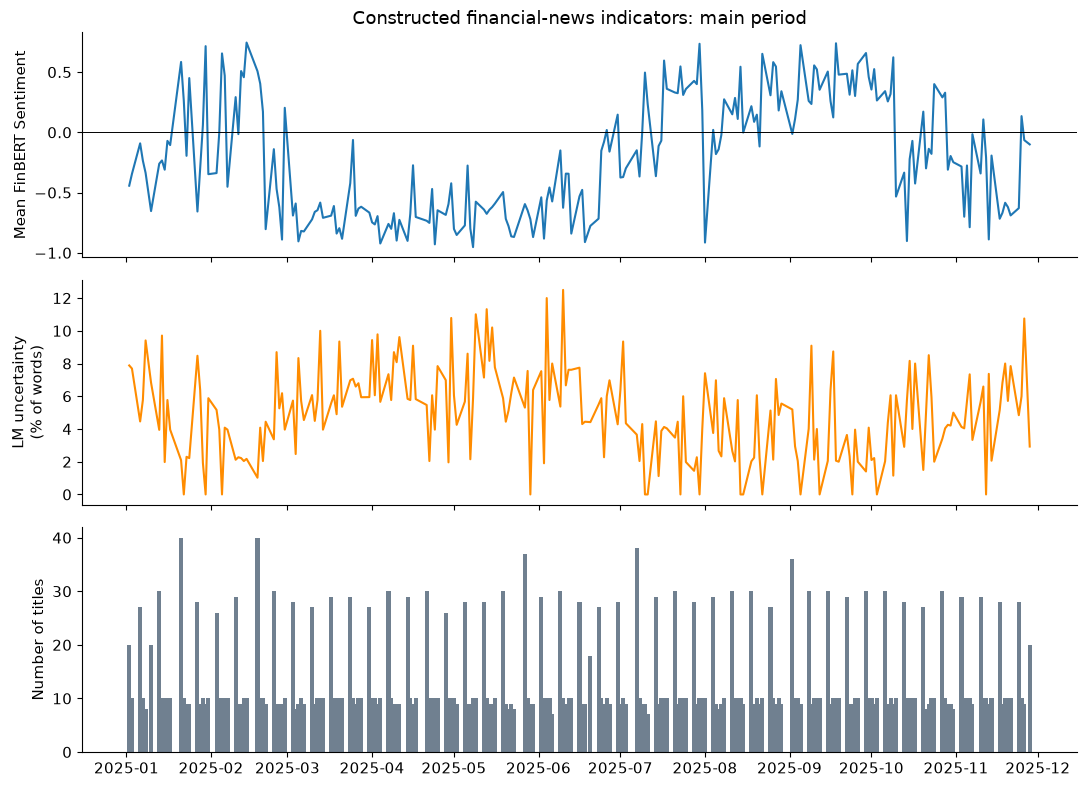

In [14]:
# Create three vertically arranged panels that share the same date axis.
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

# Panel 1: average FinBERT directional sentiment; zero is a useful reference.
axes[0].plot(main_daily.index, main_daily["finbert_sentiment"], label="FinBERT")
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_ylabel("Mean FinBERT Sentiment")
axes[0].set_title("Constructed financial-news indicators: main period")

# Panel 2: multiply the uncertainty rate by 100 to show percentage of words.
axes[1].plot(
    main_daily.index,
    100 * main_daily["lm_uncertainty"],
    color="darkorange",
)
axes[1].set_ylabel("LM uncertainty\n(% of words)")

# Panel 3: number of selected titles assigned to each session.
axes[2].bar(
    main_daily.index,
    main_daily["headline_count"],
    color="slategray",
    width=1.5,
)
axes[2].set_ylabel("Number of titles")

# Improve spacing and render the completed figure.
plt.tight_layout()
plt.show()

This figure shows three complementary features of the constructed news flow over time. The top panel measures the direction of daily tone using average FinBERT sentiment. The middle panel measures LM uncertainty as a percentage of all words used that session. The bottom panel reports the number of titles underlying those measures. The panels share the same dates, but their vertical scales and units are different; they should not be compared by numerical magnitude.

## 6. Do Financial News Indicators Move with Realised and Implied Market Risk?

### 6.1 Construct the market-risk measures and combine the daily data

| Measure | Information used | Interpretation |
|:--|:--|:--|
| **SPY realised volatility** | Historical SPY returns | How variable have observed returns been? |
| **VIX implied volatility** | Current S&P 500 option prices | How much near-term volatility is priced by the option market? |

We calculate SPY log returns from adjusted prices:

$$r_t=\log(P_t^{adj}/P_{t-1}^{adj}).$$

We retain two realised-volatility estimators from the market-risk lecture. The rolling estimator gives the most recent 21 returns equal weight:

$$\sigma_t^{roll}=SD(r_{t-20},\ldots,r_t).$$

EWMA gives more weight to recent squared returns:

$$v_t=0.94v_{t-1}+0.06r_t^2,\qquad \sigma_t^{EWMA}=\sqrt{v_t}.$$

Both are annualised using $\sqrt{252}$ and reported in percentage points. They are backward-looking because they use returns observed up to session $t$.

Cboe calculates VIX from S&P 500 option prices. It represents approximately 30-day expected volatility, expressed as an annualised percentage. A VIX level of 25 does **not** mean a 25% probability of a market fall or an expected 25% loss. VIX is forward-looking in the sense that option prices reflect expectations, but it is not a guaranteed forecast and may include a volatility risk premium.

SPY returns, realised volatility and VIX are observed market measures. Because the titles do not have verified publication times, each title was conservatively assigned to the first SPY session strictly after its issue date. Comparisons between the daily text indicators and market-risk measures therefore describe co-movement; they do not establish that news predicted the market.

In [15]:
# Reconstruct the market-risk measures introduced in Lecture 7.
# Use dates as the index so SPY, VIX and the daily text indicators
# can later be aligned by trading date.
market = spy.set_index("date").copy()

# Log price differences are continuously compounded daily SPY returns.
market["return"] = np.log(market["adj_close"]).diff()

# The code calculates two backward-looking volatility estimates: 
# rolling_vol_pct: gives the latest 21 returns equal weight;
# ewma_vol_pct: gives more weight to recent squared returns.

# Rolling volatility gives the most recent WINDOW returns equal weight.
# Multiply by sqrt(252) to annualise and by 100 to report percentage points.
market["rolling_vol_pct"] = (
    100
    * np.sqrt(252)
    * market["return"].rolling(WINDOW).std(ddof=1)
)

# EWMA applies 1-LAMBDA = 6% weight to the newest squared return and allows
# earlier observations to decay gradually. Taking the square root gives volatility.
variance = (
    market["return"]
    .pow(2)
    .ewm(alpha=1 - LAMBDA, adjust=False)
    .mean()
)
market["ewma_vol_pct"] = 100 * np.sqrt(252) * np.sqrt(variance)

# Join VIX to SPY by date. one_to_one checks for duplicate dates on either side.
market = market.join(
    vix.set_index("date"),
    how="left",
    validate="one_to_one",
)

# Add the daily text indicators using the same date index.
# SPY and volatility + VIX + FinBERT sentiment and LM uncertainty -> one combined daily table
comparison = market.join(daily, how="left", validate="one_to_one")

# Keep the stated main sample and make an independent copy for later analysis.
main = comparison.loc[MAIN_START:MAIN_END].copy()

display(main[[
    "adj_close", "return", "rolling_vol_pct", "ewma_vol_pct",
    "vix_close", "finbert_sentiment", "lm_uncertainty",
]].head(5).round(4))

,adj_close,return,rolling_vol_pct,ewma_vol_pct,vix_close,finbert_sentiment,lm_uncertainty
date,,,,,,,
2025-01-02,573.3757,-0.0025,14.3857,13.8198,17.93,-0.4429,0.0788
2025-01-03,580.5448,0.0124,15.1533,14.2433,16.13,-0.3448,0.0769
2025-01-06,583.8891,0.0057,15.1281,13.9889,16.04,-0.0913,0.0446
2025-01-07,577.2888,-0.0114,15.5641,14.2649,17.82,-0.2351,0.0577
2025-01-08,578.1323,0.0015,15.5537,13.8420,17.70,-0.3370,0.0941


### 6.2 Inspect co-movement over time

Separate panels are used because FinBERT sentiment, LM uncertainty, realised volatility and VIX are different quantities with different units. Their numerical heights should not be compared directly. Instead, we inspect whether they move at similar times.

The realised-volatility measures can rise only after large SPY returns have been observed. EWMA generally responds more quickly because it gives greater weight to recent squared returns. The 21-session rolling measure gives every return in its window equal weight and can remain high until a large return leaves that window.

VIX is derived from option prices and can change immediately as market expectations change. It can therefore rise before large returns are subsequently observed. It may also fall while realised volatility remains elevated if option-market expectations have calmed but earlier large returns are still inside the historical window.

The shaded April interval is included as a visual reference. This is a descriptive comparison, not a formal event study or a test of forecasting ability.

**Q4:** If investors become worried before a large market move, which measure could respond first? Why could VIX later fall while 21-session realised volatility remains high?


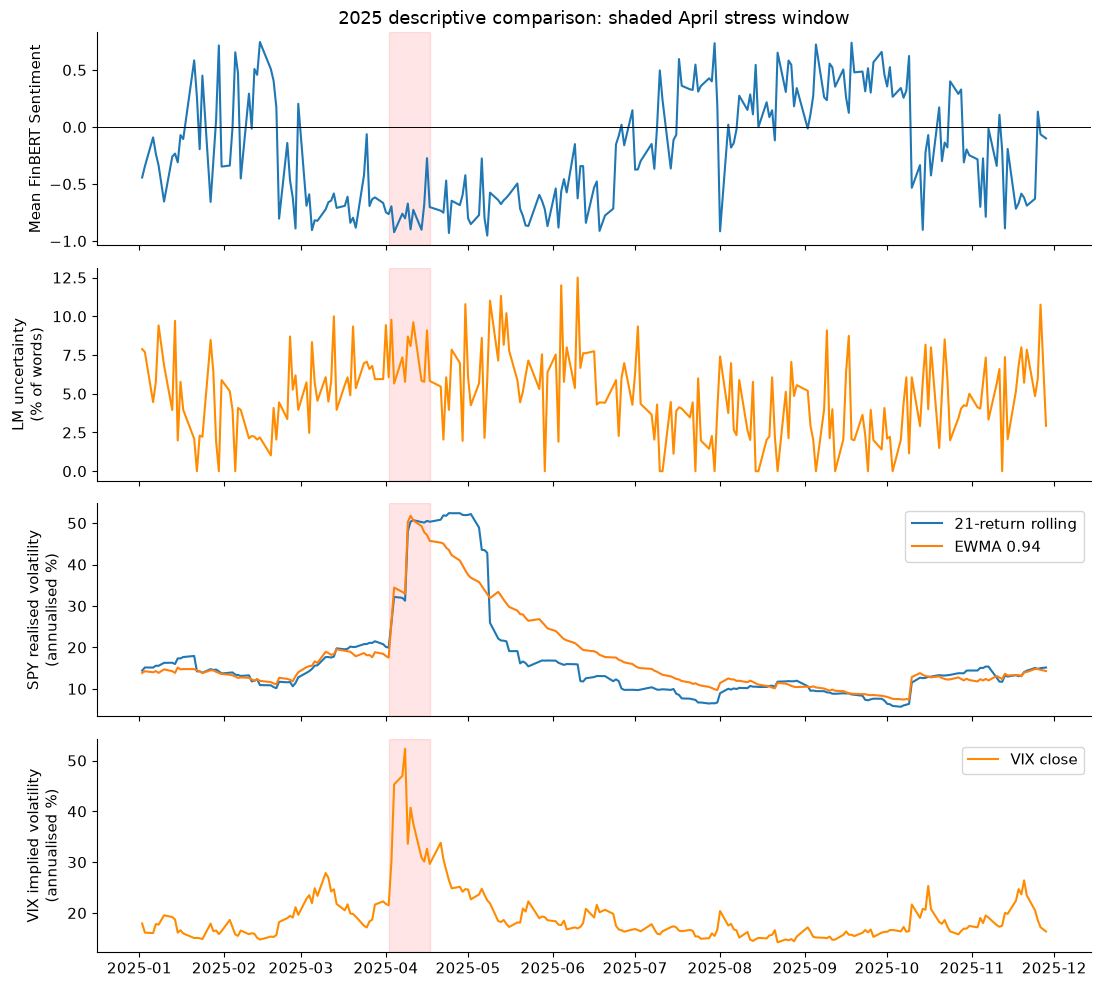

In [16]:
# Use four aligned panels so movements can be compared on the same dates.
fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)

# Text indicators.
axes[0].plot(main.index, main["finbert_sentiment"], label="Mean FinBERT sentiment")
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_ylabel("Mean FinBERT Sentiment")

# LM uncertainty is stored as a proportion, so multiply by 100
# to display it as a percentage of all words.
axes[1].plot(main.index, 100 * main["lm_uncertainty"], color="darkorange")
axes[1].set_ylabel("LM uncertainty\n(% of words)")

# Two backward-looking estimates of realised SPY volatility.
axes[2].plot(main.index, main["rolling_vol_pct"], label="21-return rolling")
axes[2].plot(main.index, main["ewma_vol_pct"], label="EWMA 0.94")
axes[2].set_ylabel("SPY realised volatility\n(annualised %)")
axes[2].legend()

# Option-implied VIX is shown separately because it is conceptually different.
axes[3].plot(main.index, main["vix_close"], color="darkorange", label="VIX close")
axes[3].set_ylabel("VIX implied volatility\n(annualised %)")
axes[3].legend()

# Shade the same April stress window in every panel.
for ax in axes:
    ax.axvspan(
        pd.Timestamp("2025-04-02"),
        pd.Timestamp("2025-04-17"),
        color="red",
        alpha=0.10,
    )

axes[0].set_title("2025 descriptive comparison: shaded April stress window")
plt.tight_layout()
plt.show()

The constructed text indicators and market-risk measures display visible co-movement during the April stress period. Headline sentiment is negative, uncertainty language is relatively elevated, and both realised and implied volatility rise. VIX falls sooner as option-market expectations calm, while backward-looking realised volatility remains elevated because April’s large returns remain in its calculation. The relationships are descriptive and expected in this constructed teaching dataset; they are not evidence that the text indicators caused or predicted market risk.

### 6.3 Quantify the designed associations

We use Pearson correlation to summarise the same-session linear association between each text indicator and each market-risk measure. A correlation ranges from −1 to +1:

- a positive value means the variables tend to increase together;
- a negative value means one tends to decrease when the other increases;
- a value closer to zero indicates a weaker linear association.

Correlations are calculated using sessions for which both variables are available, and the corresponding sample sizes are reported.

A negative correlation between FinBERT sentiment and VIX means that the constructed language tends to be more negative when VIX is higher. A positive correlation between LM uncertainty and VIX means that uncertainty words tend to be more prevalent when VIX is higher.

These relationships are expected in this teaching case because market stress influenced the mixture of synthetic headline templates. The exercise demonstrates how to calculate and interpret correlations; it does not test whether real news predicts or causes volatility. FinBERT did not receive SPY or VIX as inputs—the designed dependence entered through the synthetic-data generator.

In [17]:
# Create an empty list in which each loop result will be stored.
rows = []

# Repeat the same calculations for the two text indicators: 1. indicator = "finbert_sentiment" 2. indicator = "lm_uncertainty"
for indicator in ["finbert_sentiment", "lm_uncertainty"]:

    # Select the current text indicator and the three market-risk measures.
    columns = [
        indicator,
        "rolling_vol_pct",
        "ewma_vol_pct",
        "vix_close",
    ]

    # Retain only sessions where all four selected values are available.
    pair = main[columns].dropna()

    # Store the sample size and three correlations as one dictionary.
    rows.append({
        "text_indicator": indicator,
        "paired_sessions": len(pair),
        "corr_rolling_vol": pair[indicator].corr(
            pair["rolling_vol_pct"]
        ),
        "corr_ewma_vol": pair[indicator].corr(
            pair["ewma_vol_pct"]
        ),
        "corr_vix": pair[indicator].corr(
            pair["vix_close"]
        ),
    })

# Convert the two stored dictionaries into a two-row results table.
correlations = pd.DataFrame(rows)
display(correlations.round(3))

,text_indicator,paired_sessions,corr_rolling_vol,corr_ewma_vol,corr_vix
0,finbert_sentiment,228,-0.524,-0.599,-0.593
1,lm_uncertainty,228,0.313,0.386,0.346


The constructed text indicators exhibit the intended same-session association with market risk: sentiment becomes more negative and uncertainty language becomes more prevalent during higher-risk sessions. These correlations describe the designed teaching data and do not demonstrate prediction, causation, or performance on real financial news.

## Final teaching case — April 2025 market stress

On 2 April 2025, the US administration announced a broad reciprocal-tariff policy. On 9 April, it announced a 90-day suspension of the higher country-specific rates for most listed trading partners, effective 10 April. The additional 10% duty generally remained, while China was excluded from the suspension.

The Federal Reserve's November 2025 Financial Stability Report records a sharp rise in equity-market volatility in April. We inspect our synthetic titles, SPY realised-volatility calculations and VIX closing levels.

Sources: [2 April order](https://www.whitehouse.gov/presidential-actions/2025/04/regulating-imports-with-a-reciprocal-tariff-to-rectify-trading-practices-that-contribute-to-large-and-persistent-annual-united-states-goods-trade-deficits/), [9 April order](https://www.whitehouse.gov/presidential-actions/2025/04/modifying-reciprocal-tariff-rates-to-reflect-trading-partner-retaliation-and-alignment/), [Federal Reserve report](https://www.federalreserve.gov/publications/november-2025-financial-stability-report-asset-valuations.htm).

Policy announcements can change expectations about firms' costs, demand, inflation and trade, allowing option prices to reprice implied volatility quickly. Realised volatility rises only when large returns occur and may remain elevated while those returns remain inside the historical window. Both large losses and large gains contribute to high realised volatility.

The headlines are not records of the April announcements. Their sentiment mixture was mechanically generated from market-stress conditions, so this is a transparent simulation rather than an event study or forecasting exercise.

In [18]:
# Select synthetic titles assigned to the market sessions surrounding
# the two April policy announcements. Also require the title to contain
# the whole word "tariff", "tariffs" or "trade".
case_titles = news.loc[
    news["session_date"].between("2025-04-03", "2025-04-10")
    & news["title_clean"].str.contains(
        r"\b(?:tariffs?|trade)\b",
        case=False,
        regex=True,
        na=False,
    )
]
# Keep the variables needed to discuss each selected title.
case_columns = [
    "issue_date",
    "session_date",
    "title_clean",
    "sentiment_score",
    "lm_uncertainty",
]
# Sort by market session, show the first eight titles and create
# a separate display table so the original data remain unchanged.
case_display = (
    case_titles[case_columns]
    .sort_values(["session_date", "issue_date"])
    .head(8)
    .copy()
)
# Round only the displayed values; the stored calculations are unchanged.
case_display[["sentiment_score", "lm_uncertainty"]] = (
    case_display[["sentiment_score", "lm_uncertainty"]].round(3)
)
display(case_display)

,issue_date,session_date,title_clean,sentiment_score,lm_uncertainty
1761,2025-04-02,2025-04-03,Investors assess possible tariff risks for Synthetic Energy Firm 01831,0.102,0.222
1762,2025-04-02,2025-04-03,Investors assess possible tariff risks for Synthetic Manufacturing Firm 01834,0.153,0.222
1769,2025-04-02,2025-04-03,Synthetic Transport Firm 01839 faces uncertain revenues amid possible changes in trade policy,-0.944,0.167
1771,2025-04-03,2025-04-04,Synthetic Banking Firm 01844 faces uncertain revenues amid possible changes in trade policy,-0.952,0.167
1780,2025-04-04,2025-04-07,Investors assess possible tariff risks for Synthetic Transport Firm 01854,0.087,0.222
1785,2025-04-04,2025-04-07,Synthetic Banking Firm 01853 faces uncertain revenues amid possible changes in trade policy,-0.948,0.167
1787,2025-04-04,2025-04-07,Synthetic Insurance Firm 01858 faces uncertain revenues amid possible changes in trade policy,-0.944,0.167
1800,2025-04-06,2025-04-07,Investors assess possible tariff risks for Synthetic Energy Firm 01874,0.095,0.222


The selected synthetic titles contain trade-related language during the April case window, but they are not historical records of the policy announcements. Their results illustrate how FinBERT sentiment and LM uncertainty can describe different aspects of the same text. The exercise is a transparent simulation, not an event study or forecasting test.

### Compare averages before, during and after the stress window

We now move from individual titles to period-level summaries. For each period, we calculate the mean of the daily text indicators and market-risk measures. Each trading session receives equal weight.

The periods contain different numbers of trading sessions, so we report the session count. These descriptive averages help us compare conditions around the April episode, but they are not a formal event study or a statistical significance test.

In [19]:
# Each tuple contains a period label, start date and end date.
periods = [
    ("Before", "2025-03-03", "2025-04-01"),
    ("Stress window", "2025-04-02", "2025-04-17"),
    ("After", "2025-04-21", "2025-05-16"),
]

# Store one summary dictionary for each period.
rows = []

for name, start, end in periods:

    # Select all trading sessions from start through end, inclusive.
    part = main.loc[start:end]

    # Calculate the number of sessions and the mean daily value
    # of each text and market-risk indicator.
    rows.append({
        "period": name,
        "sessions": len(part),
        "mean_finbert_sentiment": part["finbert_sentiment"].mean(),
        "mean_lm_uncertainty_pct": (
            100 * part["lm_uncertainty"].mean()
        ),
        "mean_rolling_vol_pct": part["rolling_vol_pct"].mean(),
        "mean_ewma_vol_pct": part["ewma_vol_pct"].mean(),
        "mean_vix_level": part["vix_close"].mean(),
    })

# Convert the three dictionaries into a three-row comparison table.
case_summary = pd.DataFrame(rows)
display(case_summary.round(3))

,period,sessions,mean_finbert_sentiment,mean_lm_uncertainty_pct,mean_rolling_vol_pct,mean_ewma_vol_pct,mean_vix_level
0,Before,22,-0.673,6.231,18.649,17.904,21.838
1,Stress window,12,-0.733,7.295,40.960,40.570,35.946
2,After,20,-0.672,6.667,41.512,37.034,23.604


Text tone is more negative and LM uncertainty is higher during the stress window than before it. VIX and both realised-volatility estimates also increase substantially. After the window, sentiment and VIX move back toward their earlier levels, while realised volatility remains elevated because the April returns still influence the backward-looking estimators. These patterns illustrate the mechanics of the constructed teaching case and should not be interpreted as evidence of prediction or causation.

### Q5 — Explain the evidence

Using the before/during/after table, write four sentences with your group:

1. Report one change in FinBERT sentiment or LM uncertainty, including its units.
2. Report one change in SPY realised volatility or VIX, including its units.
3. Explain why VIX and realised volatility may not move at exactly the same time.
4. Explain why this simulation demonstrates a measurement workflow but does not show that real news predicts volatility.

The synthetic data were designed to contain more negative and uncertain language during high-stress periods. The relevant question is whether the LM and FinBERT indicators recover that designed pattern and how the meanings of those indicators differ.

### Key takeaway

We converted financial text into daily sentiment and uncertainty indicators and examined their relationships with realised and implied market risk. The results demonstrate the measurement process, not prediction or causation.

## References and data preparation

- Loughran, T. & McDonald, B. (2011). *When Is a Liability Not a Liability? Textual Analysis, Dictionaries, and 10-Ks.* Journal of Finance, 66(1), 35–65. [Official dictionary](https://sraf.nd.edu/loughranmcdonald-master-dictionary/).
- Araci, D. (2019). *FinBERT: Financial Sentiment Analysis with Pre-trained Language Models.* [arXiv:1908.10063](https://arxiv.org/abs/1908.10063).
- [ProsusAI FinBERT model](https://huggingface.co/ProsusAI/finbert). The accompanying `Prepare_synthetic_FinBERT_scores.ipynb` documents the exact frozen-score preparation.
- [Cboe VIX historical data](https://www.cboe.com/tradable_products/vix/vix_historical_data/) and [Cboe VIX FAQ](https://www.cboe.com/tradable_products/vix/faqs/).
- [Yahoo Finance SPY history](https://finance.yahoo.com/quote/SPY/history/).
- Synthetic titles: Generated locally by `Prepare_synthetic_financial_news_data.ipynb`. The mixture of title templates was deliberately conditioned on SPY and VIX market-stress measures. These titles are a teaching simulation, not observed news.